[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Naviden/Introduction-to-XAI/blob/main/Theory/Dimensions.ipynb)

[Colab setup: dependencies and repository files](https://github.com/Naviden/Introduction-to-XAI/blob/main/docs/REPRODUCIBILITY.md#google-colab)

# Dimensions of explanations: from context to a message

This notebook follows **Figure 1 and Sections 3–5** of:

**Cambria, E., Malandri, L., Mercorio, F., Mezzanzanica, M., & Nobani, N. (2023). _A survey on XAI and natural language explanations_. Information Processing & Management, 60(1), 103111. [https://doi.org/10.1016/j.ipm.2022.103111](https://doi.org/10.1016/j.ipm.2022.103111).**

The paper surveys 70 works from 2006–2021 and emphasizes how explanations reach their intended audience, especially through natural language. Its roadmap has three stages: **Context definition → Explanation generation → Message generation**. It is a framework for selecting and communicating explanations, not a ranking of every current XAI algorithm.

We use the paper's six dimensions to organize runnable examples. Method assignments and examples below are this notebook's teaching applications of the roadmap; they are not new survey results. Additional practical checks are labelled separately at the end.

## Figure 1: the paper's roadmap

![Figure 1: explanation goal and audience define context; explanator type, structure and explanation type generate a raw explanation; presentation turns it into a message for the audience.](../../../Theory/images/cambria-2023-figure-1.png)

**Figure 1, Cambria et al. (2023), p. 4.** Original figure and caption extracted from the supplied published PDF; the surrounding page was cropped away, with no relabelling. © 2022 Elsevier Ltd. This figure retains its original rights and is excluded from the repository's CC BY 4.0 grant. [Full-size figure](../../../Theory/images/cambria-2023-figure-1.png) · [Source article](https://doi.org/10.1016/j.ipm.2022.103111) · [Extraction provenance](../../../Theory/images/README.md).

Read the arrows as a design process: specify the context, produce an explanation artefact, and then choose how to communicate it. A plot, rule or fluent sentence alone does not determine the explanation goal or establish that the message helps its audience.

### The six dimensions shown in Figure 1

| Stage | Dimension | Examples listed in the figure |
|---|---|---|
| Context definition | Explanation Goal | Model Explanation; Outcome Explanation; Model Inspection |
| Context definition | Audience | Decision-subject; Data-subject; Examiner; Creator; Operator; Executor |
| Explanation generation | Explanator Type | Decision trees; Decision rules; Salient masks; Prototype selection; Neuron activation |
| Explanation generation | Structure | Feature importance; Sensitivity analysis; Direct Answers |
| Explanation generation | Explanation Type | Plain-fact; Contrastive; Counterfactual |
| Message generation | Presentation | Graphics; Images; Reports; Texts; Dialogue System |

**Reading the figure together with the paper.** The figure's illustrative lists and the survey's operational categories are not identical. Section 3.2 / Table 1 group audiences as **End users, Developers, Decision-makers**. Section 4.1 / Table 1 use **Feature Inspection (FIN)** alongside trees, rules and masks; Figure 1 instead also shows prototype selection and neuron activation. Section 5.1 groups presentation into **Graphics/plots, Texts, Images, Reports**, discussing dialogue within its natural-language treatment; Table 1 uses Graphic, Image, Rule, Text and Dialogue System. We preserve these distinctions rather than present a merged list as an exact transcription.

In particular, **Feature Inspection** is an explanator category in the prose; **Feature importance** is a structure. They are different dimensions.

## Setup

Use the full teaching dependencies in [`requirements.txt`](../../../requirements.txt), including XGBoost and DiCE. Run from the repository checkout. Iris and diabetes are bundled with scikit-learn; the Adult example uses a checked UCI download on first use. See the [asset manifest](../../../assets/manifest.json) and [download guidance](../../ASSETS.md).

All examples below explain fitted model behaviour. They do not establish causal mechanisms or validate a clinical or employment decision system.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "assets/manifest.json").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from xai_assets import load_adult_dataframe, verify_file

verify_file(
    ROOT / "Theory/images/cambria-2023-figure-1.png",
    "7087134236c6d46aa7f198b776d483afda640f4e1c5a92c38a8580b4cfbce65b",
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_iris, load_diabetes
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

SEED = 42

## 1. Context definition: goal and audience

### Explanation goal (paper §3.1)

- **Model Explanation:** fit an interpretable surrogate that mimics a black box. Its agreement with the black box is **fidelity**, which must be assessed over a stated population. A global importance chart is not, by itself, this kind of surrogate.
- **Outcome Explanation:** explain a selected prediction for a selected input. Our held-out SHAP case and DiCE query serve this goal.
- **Model Inspection:** expose aspects of the fitted model's mechanism through a representation, without necessarily fitting a surrogate. The forest's training impurity-importance chart below is a limited inspection summary.

Local/global scope is useful but does not replace these three goals. An inspection can summarize a model globally; a surrogate can also be used locally. The paper discusses transparent-box design as background, while Figure 1 follows an explanation pipeline around a black box.

### Audience (paper §3.2)

| Role shown in Figure 1 | Example need in a classifier application |
|---|---|
| Creator | Debug or improve the implemented model and pipeline |
| Operator | Understand how to use the system's output during operation |
| Executor | Decide how to act on a recommendation |
| Decision-subject | Understand a decision that affects them |
| Data-subject | Understand how data about them is used |
| Examiner | Audit or investigate the system |

The paper attributes these roles to Tomsett et al. and then uses the broader end-user/developer/decision-maker grouping for its survey coding. Roles can overlap. For the following Iris example, we choose a **developer/creator** audience and distinguish model inspection from model explanation.

In [2]:
iris = load_iris(as_frame=True)
iris_train, iris_test, iris_y_train, iris_y_test = train_test_split(
    iris.data, iris.target, test_size=0.3, random_state=SEED, stratify=iris.target
)
iris_forest = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=2)
iris_forest.fit(iris_train, iris_y_train)
forest_test_labels = iris_forest.predict(iris_test)
print(f"Forest held-out accuracy against observed labels: {accuracy_score(iris_y_test, forest_test_labels):.3f}")

Forest held-out accuracy against observed labels: 0.889


### Model inspection: a global importance summary

This plot summarizes normalized reductions in training impurity within the fitted forest. Its **structure** is feature importance and its **presentation** is a bar plot. The values can be affected by correlated predictors and feature cardinality; they are neither held-out performance drops nor causal effects. The declared inspection question is: *which features accumulated the most impurity reduction during training?*

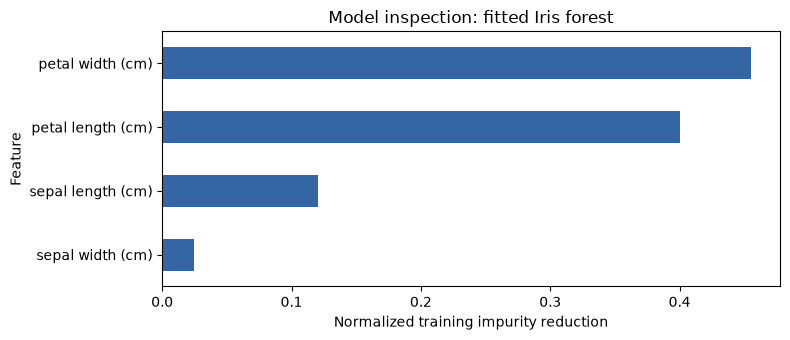

In [3]:
impurity = pd.Series(iris_forest.feature_importances_, index=iris.data.columns)
assert np.isfinite(impurity).all()
np.testing.assert_allclose(impurity.sum(), 1.0)
fig, ax = plt.subplots(figsize=(8, 3.5))
impurity.sort_values().plot.barh(ax=ax, color="#3465a4")
ax.set(xlabel="Normalized training impurity reduction", ylabel="Feature",
       title="Model inspection: fitted Iris forest")
plt.tight_layout()
plt.show()

### Model explanation: an interpretable surrogate

A small tree learns the **forest's predicted labels on training inputs**, rather than being fitted directly to the observed Iris labels. Evaluate it on held-out inputs using two distinct questions: does it mimic the forest (fidelity), and does it predict observed labels (accuracy)? High agreement on this split does not prove equivalence over every possible input.

,Quantity,Held-out value
0,Surrogate agreement with forest,0.911111
1,Surrogate accuracy against observed labels,0.977778


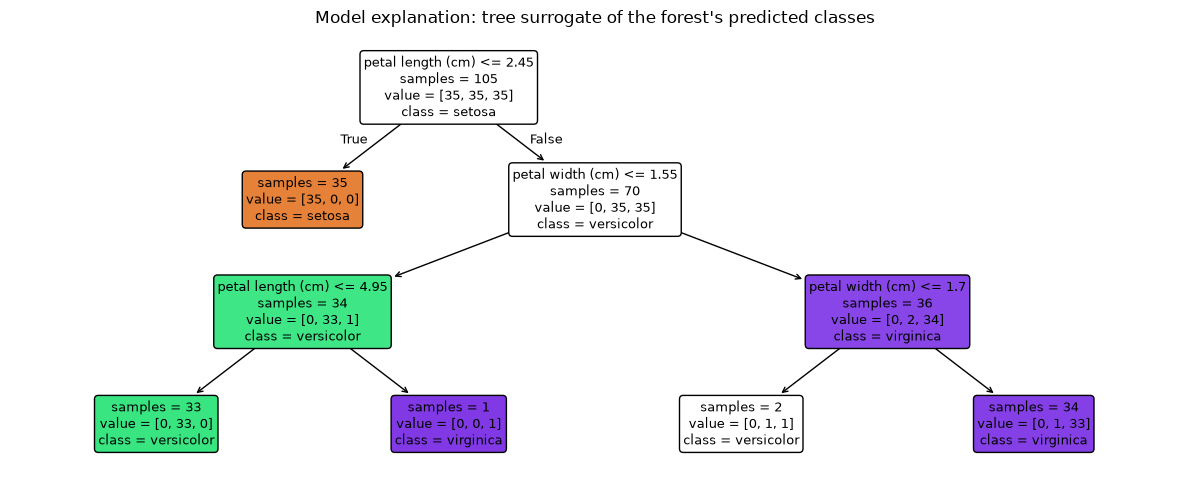

In [4]:
surrogate = DecisionTreeClassifier(max_depth=3, random_state=SEED)
surrogate.fit(iris_train, iris_forest.predict(iris_train))
surrogate_test_labels = surrogate.predict(iris_test)
fidelity = accuracy_score(forest_test_labels, surrogate_test_labels)
surrogate_accuracy = accuracy_score(iris_y_test, surrogate_test_labels)
assert 0 <= fidelity <= 1
assert set(iris_train.index).isdisjoint(iris_test.index)
display(pd.DataFrame({
    "Quantity": ["Surrogate agreement with forest", "Surrogate accuracy against observed labels"],
    "Held-out value": [fidelity, surrogate_accuracy],
}))
fig, ax = plt.subplots(figsize=(12, 5))
plot_tree(surrogate, feature_names=list(iris.data.columns), class_names=list(iris.target_names),
          filled=True, rounded=True, impurity=False, ax=ax, fontsize=9)
ax.set_title("Model explanation: tree surrogate of the forest's predicted classes")
plt.tight_layout()
plt.show()

## 2. Explanation generation: artefact, structure and question

### Explanator type (paper §4.1)

This dimension concerns the mechanism or artefact used to generate an explanation. Figure 1 shows trees, rules, salient masks, prototypes and neuron activations; §4.1 also names feature inspection. Our small surrogate is a **decision tree**. The SHAP example below is a teaching application of the prose's **feature-inspection** category. For other artefacts, see [rules](../../../Tools/RuleFit_examples/RuleFit_example.ipynb) and the [shared image comparison](../../../Tools/NeuralComparison_examples/Shared_Image_Attribution.ipynb). This notebook does not implement every type pictured in the figure.

### Structure (paper §4.2)

| Structure | Question and output | Example in this repository |
|---|---|---|
| Feature importance | Which features receive importance or contribution values for the stated target? | The impurity chart and local SHAP contributions below, with different definitions and units |
| Sensitivity analysis | How does model output change when inputs or model/training settings change? | [PDP/ICE](../../../Tools/Visual%20Explanation_example/PDP_ICE.ipynb), [evaluation and sensitivity](../../../Tools/Evaluation_examples/Evaluation_and_Sensitivity.ipynb) |
| Direct Answers | Address an explicit what/how/why or what-if question | The model-level counterfactual question below |

The authors describe the first two as potentially restricted forms of direct answers. These are useful descriptions of how an explanation is organized, not mutually exclusive mathematical sets. A feature-importance value alone does not explain a real-world root cause.

### Outcome explanation: one held-out regression prediction

We now use a separate, bundled diabetes-regression task. The selected target is the model's numeric predicted response, and the case is fixed as the fifth test row. This is not the Iris surrogate's target or dataset.

Held-out RMSE: 59.064 response units
Held-out R²: 0.342
Case index: 73; baseline + contributions = 131.022


/Users/navid/Documents/Codex/2026-10-28/makew/work/Introduction-to-XAI/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


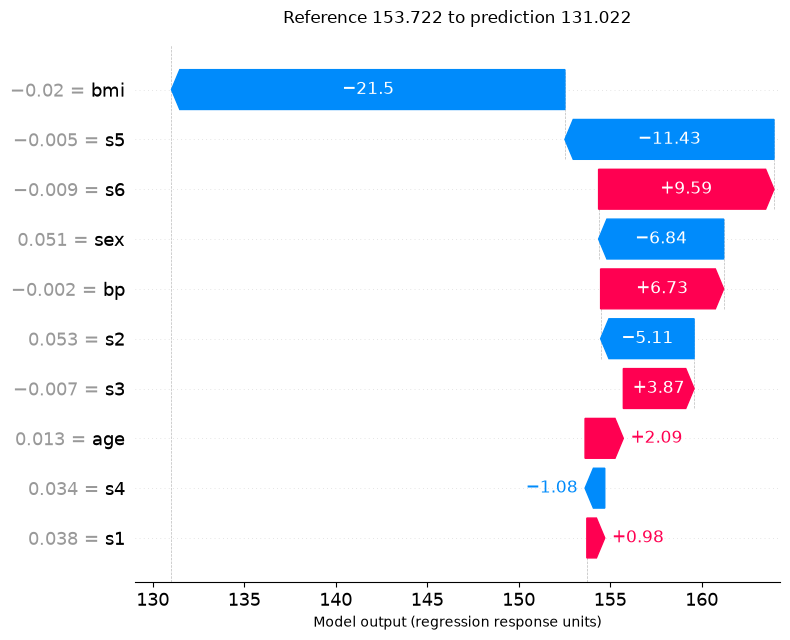

In [5]:
import xgboost
import shap

reg_X, reg_y = load_diabetes(return_X_y=True, as_frame=True)
reg_train, reg_test, reg_y_train, reg_y_test = train_test_split(
    reg_X, reg_y, test_size=0.2, random_state=SEED
)
reg_model = xgboost.XGBRegressor(
    n_estimators=100, max_depth=3, random_state=SEED, n_jobs=2
).fit(reg_train, reg_y_train)
reg_predictions = reg_model.predict(reg_test)
print(f"Held-out RMSE: {np.sqrt(mean_squared_error(reg_y_test, reg_predictions)):.3f} response units")
print(f"Held-out R²: {r2_score(reg_y_test, reg_predictions):.3f}")

reg_explainer = shap.TreeExplainer(reg_model, feature_perturbation="tree_path_dependent")
reg_explanations = reg_explainer(reg_test)
case_position = 4
case_explanation = reg_explanations[case_position]
case_prediction = float(reg_predictions[case_position])
case_baseline = float(case_explanation.base_values)
case_contributions = np.asarray(case_explanation.values, dtype=float)
np.testing.assert_allclose(case_baseline + case_contributions.sum(), case_prediction, rtol=1e-5, atol=1e-3)
print(f"Case index: {reg_test.index[case_position]}; baseline + contributions = {case_prediction:.3f}")
shap.plots.waterfall(case_explanation, show=False)
# Use one clear header instead of SHAP's overlapping near-identical twin-axis ticks.
fig = plt.gcf()
for extra_axis in fig.axes[1:]:
    extra_axis.remove()
ax = fig.axes[0]
ax.set_title(f"Reference {case_baseline:.3f} to prediction {case_prediction:.3f}", pad=16)
ax.set_xlabel("Model output (regression response units)")
plt.tight_layout()
plt.show()

The SHAP **structure** is a set of feature contributions; the waterfall is its **presentation**. Positive contributions raise the explained model output relative to the baseline, and negative contributions lower it. Here baseline and contributions are in diabetes-regression response units, not probability points.

The tree-path-dependent reference uses information about training samples along tree paths. The base value is not generally an observed target mean or a model intercept. The contributions and reference reconstruct the selected model prediction, as checked above. Changing how missing features or dependence are handled changes the explanation question. These values do not establish causal effects on disease progression. See [the SHAP guide](../../../Tools/SHAP_examples/How%20SHAP%20works.md).

### Explanation type (paper §4.3)

Figure 1 uses **Plain-fact, Contrastive and Counterfactual**. Section 4.3 discusses broader theories as background, including covering-law, statistical-relevance and functional accounts; those are not extra boxes in Figure 1.

| Type or contrast | Original teaching question |
|---|---|
| Plain-fact | Which features contribute to this model prediction relative to its reference? |
| Contrastive, P-contrast | Why did this input receive class A rather than class B? |
| Contrastive, O-contrast | Why did input a receive A while input b received B? |
| Contrastive, T-contrast | Why did the same input/object receive A at time t₀ and B at time t₁? |
| Counterfactual | Which hypothetical input would receive the desired model output? |

For a contrastive question, specify the **fact** (actual decision), the **foil** (alternative decision), and the **contrast class** (available alternatives). For T-contrast, distinguish changing data from a changing model or pipeline. A counterfactual input can answer a contrastive question, so these labels need not be disjoint.

### A counterfactual question with an explicit fact and foil

For a fitted Adult-income classifier, the contrast class is {0: income ≤50K, 1: income >50K}. The fact is the selected query's model-predicted class; the foil is its opposite. DiCE searches for candidate rows assigned the foil. This illustrates a **model-level** question, not an intervention that guarantees a real income change.

In [6]:
import dice_ml
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

adult = load_adult_dataframe()
adult_train, adult_test = train_test_split(
    adult, test_size=0.2, random_state=SEED, stratify=adult["income"]
)
continuous_features = ["age", "hours_per_week"]
adult_X_train = adult_train.drop(columns="income")
categorical_features = adult_X_train.columns.drop(continuous_features).tolist()
preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("continuous", "passthrough", continuous_features),
])
adult_model = make_pipeline(
    preprocessor, RandomForestClassifier(n_estimators=50, max_depth=10, random_state=SEED, n_jobs=2)
)
adult_model.fit(adult_X_train, adult_train["income"])
print(f"Income classifier held-out accuracy: {adult_model.score(adult_test.drop(columns='income'), adult_test['income']):.3f}")

query = adult_test.drop(columns="income").iloc[[0]]
fact = int(adult_model.predict(query)[0])
foil = 1 - fact
print(f"Contrast class: {{0, 1}}; fact: {fact}; foil: {foil}")
dice_data = dice_ml.Data(dataframe=adult_train, continuous_features=continuous_features, outcome_name="income")
dice_model = dice_ml.Model(model=adult_model, backend="sklearn")
dice_explainer = dice_ml.Dice(dice_data, dice_model, method="random")

Income classifier held-out accuracy: 0.835
Contrast class: {0, 1}; fact: 0; foil: 1


In [7]:
dice_result = dice_explainer.generate_counterfactuals(
    query, total_CFs=4, desired_class=foil, random_seed=SEED
)
candidates = dice_result.cf_examples_list[0].final_cfs_df
assert candidates is not None and len(candidates) > 0, "No candidate found in this search"
candidate_features = candidates.drop(columns="income")
checked_predictions = adult_model.predict(candidate_features)
assert np.all(checked_predictions == foil), "A displayed candidate did not reach the requested model class"
dice_result.visualize_as_dataframe()
print(f"Verified {len(candidates)} candidate predictions against the fitted pipeline.")

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00,  3.96it/s]

100%|██████████| 1/1 [00:00<00:00,  3.96it/s]

Query instance (original outcome : 0)


,age,workclass,education,marital_status,occupation,race,gender,hours_per_week,income
0,22,Private,HS-grad,Single,Blue-Collar,White,Male,16,0



Diverse Counterfactual set (new outcome: 1)


,age,workclass,education,marital_status,occupation,race,gender,hours_per_week,income
0,77,Private,Prof-school,Married,Blue-Collar,White,Male,72,1
1,73,Private,Doctorate,Widowed,Other/Unknown,White,Male,88,1
2,34,Private,Prof-school,Single,Sales,White,Male,16,1
3,46,Government,Prof-school,Single,Blue-Collar,White,Male,16,1


Verified 4 candidate predictions against the fitted pipeline.


Read each changed coordinate beside the original row. This deliberately unconstrained demonstration does not establish minimality, plausible feature combinations or a usable action plan; it can change attributes that should not be treated as available actions. A prediction flip is the check performed here, not a feasibility or causal guarantee. See the [constrained DiCE example](../../../Tools/DiCE_examples/DiCE_example.ipynb) and [causal-recourse lab](../../../Tools/CausalRecourse_examples/Causal_Recourse.ipynb).

In Figure 1 terms, we have an outcome-explanation goal, a counterfactual question and a table/report presentation. Calling the output a report says how it is communicated, not how the candidates were generated.

## 3. Message generation: communicate the explanation

Section 5 turns raw explanation artefacts into messages for an audience. Its presentation families include graphics/plots, images, reports and texts; Figure 1 also displays dialogue systems. The same raw explanation can support several presentations:

| Presentation | What the reader sees | Distinction to retain |
|---|---|---|
| Graphics/plots | Bar chart, waterfall, tree or other plot | A plotting choice is not an explanation algorithm |
| Images | Image heatmap, salient mask or annotated input image | A heatmap over pixels differs from a numeric heatmap plot |
| Reports | Tabular results, decision tables or combined reports | Structure the evidence and its context |
| Texts | Rules, word annotations or natural-language sentences | Textual output is not necessarily natural-language generation |
| Dialogue System | A conversation with user questions and follow-up responses | A single generated paragraph does not implement dialogue management |

The paper distinguishes **template-based** and **end-to-end** natural-language generation (§5.1). Below, a small template-filling example converts the *same checked SHAP result* into audience-specific text. The plotted result above, the table below and these messages share the same case, target, reference and numerical values. No language model or conversation manager is involved.

In [8]:
contribution_table = pd.DataFrame({
    "Feature": reg_test.columns,
    "Input value": reg_test.iloc[case_position].to_numpy(),
    "SHAP contribution (response units)": case_contributions,
}).sort_values("SHAP contribution (response units)", key=np.abs, ascending=False)
display(contribution_table)

largest_index = int(np.argmax(np.abs(case_contributions)))
largest_feature = str(reg_test.columns[largest_index])
largest_value = float(case_contributions[largest_index])
direction = "upward" if largest_value >= 0 else "downward"
residual = case_prediction - (case_baseline + case_contributions.sum())
messages = {
    "Developer / creator": (
        f"For test row {reg_test.index[case_position]}, the tree-path-dependent SHAP base is "
        f"{case_baseline:.3f}; contributions sum to {case_contributions.sum():+.3f}. "
        f"The explained output is {case_prediction:.3f}; reconstruction residual {residual:.6f}."
    ),
    "End user / decision-subject": (
        f"The model's score for this example is {case_prediction:.1f}, compared with its "
        f"reference score of {case_baseline:.1f}. The largest contribution by magnitude "
        f"comes from {largest_feature}, in the {direction} direction. This describes "
        "the model's calculation, not what would happen if that measurement changed."
    ),
    "Decision-maker / executor": (
        f"The reported model score is {case_prediction:.1f} response units. This explanation "
        "accounts for the prediction relative to a reference; it does not show that the "
        "prediction is correct for this case or that any proposed action will improve an outcome."
    ),
}
assert abs(residual) < 1e-3
for audience, message in messages.items():
    print(audience)
    print(message)
    print()


,Feature,Input value,SHAP contribution (response units)
2,bmi,-0.020218,-21.501841
8,s5,-0.005142,-11.426146
9,s6,-0.009362,9.585394
1,sex,0.050680,-6.837141
3,bp,-0.002228,6.726860
5,s2,0.053174,-5.109718
6,s3,-0.006584,3.868067
0,age,0.012648,2.091115
7,s4,0.034309,-1.076999
4,s1,0.038334,0.980290


Developer / creator
For test row 73, the tree-path-dependent SHAP base is 153.722; contributions sum to -22.700. The explained output is 131.022; reconstruction residual -0.000031.

End user / decision-subject
The model's score for this example is 131.0, compared with its reference score of 153.7. The largest contribution by magnitude comes from bmi, in the downward direction. This describes the model's calculation, not what would happen if that measurement changed.

Decision-maker / executor
The reported model score is 131.0 response units. This explanation accounts for the prediction relative to a reference; it does not show that the prediction is correct for this case or that any proposed action will improve an outcome.



The audience labels above combine the paper's broader survey groups with illustrative Figure 1 roles; they are not one-to-one equivalences. The messages are **original teaching templates**, not quotations or empirically validated user-facing explanations.

Content selection matters: the short end-user message omits most contributions, so the full table remains available. A fluent message can still be incomplete, misleading or unhelpful. Test numerical faithfulness, comprehension, task performance and appropriate reliance separately. A claim that one wording helps people requires human evidence; this notebook supplies none. See the [human-study materials](../../HUMAN_STUDY.md).

## Map the examples back to the roadmap

The following is our application of Cambria et al.'s framework, rather than the paper's coding of these particular experiments.

| Example | Context / goal | Generation | Presentation |
|---|---|---|---|
| Forest impurity chart | Developer; limited Model Inspection | Feature-importance structure | Graphics/bar plot |
| Tree surrogate | Developer; Model Explanation | Decision-tree explanator; plain-fact description of a fitted approximation | Tree graphic plus fidelity report |
| Held-out SHAP case | Selected audience; Outcome Explanation | Feature inspection (§4.1); feature-contribution structure; plain-fact question | Waterfall, contribution table and bounded template text |
| DiCE candidates | Explicit fact and foil; Outcome Explanation | Direct-answer structure for a counterfactual question | Tabular report |

A method name alone does not fill all six dimensions. For example, “SHAP” does not specify who reads the explanation or which message they receive. Conversely, choosing “text” does not establish what explanatory computation supports it.

## Additional practical dimensions and checks

**Repository guidance beyond Figure 1.** The following axes complement the paper's roadmap; they are not presented as its six dimensions.

| Additional axis | Choices / checks |
|---|---|
| Scope | Local case, subgroup or stated global population |
| Model access | Model-specific or model-agnostic; exact APIs/internals available |
| Construction | Intrinsic model or post-hoc explanation/surrogate |
| Target and units | Class and output being explained: score, probability, log-odds or regression response |
| Reference and perturbations | Background sample, missing-feature semantics, masking or replacement rule |
| Claim | Predictive description versus an intervention under explicit causal assumptions |
| Evaluation | Model quality, explanation fidelity/stability, and human utility as separate questions |

The paper also develops preference-dependent method selection with AHP in §6. Such a ranking depends on chosen criteria, weights and survey coding; it is not an empirical leaderboard proving one method is universally best. We do not implement or reproduce that ranking here.

### Short exercises

1. Keep the same SHAP result but change the audience from creator to examiner. State what evidence the message must add, and identify which roadmap dimension changed.
2. Compare the forest's held-out accuracy with the surrogate's fidelity. Explain why neither quantity alone answers both questions.
3. Name the fact, foil and contrast class for the DiCE query. List two constraints that would be needed before treating a candidate as an action plan.
4. Choose a method from the [method guide](../../METHOD_GUIDE.md) and fill all six Figure 1 dimensions, distinguishing choices made by the method from choices made by its application.

## Reference and further reading

Cambria, E., Malandri, L., Mercorio, F., Mezzanzanica, M., & Nobani, N. (2023). **A survey on XAI and natural language explanations.** *Information Processing & Management*, **60**(1), 103111. [doi:10.1016/j.ipm.2022.103111](https://doi.org/10.1016/j.ipm.2022.103111). Figure 1 is on p. 4; the six dimensions are developed in §§3–5. The article appeared online on 25 October 2022 and belongs to the 2023 journal volume. [BibTeX](../../../Theory/references.bib).

The notebook's mappings, numerical demonstrations and supplementary cautions are original teaching material. For implementation details and primary method references, see [SHAP](../../../Tools/SHAP_examples/How%20SHAP%20works.md), [DiCE](../../../Tools/DiCE_examples/How%20DiCE%20works.md), the [evaluation protocol](../../EVALUATION.md) and [method-selection guide](../../METHOD_GUIDE.md).